# TP 3 — Apprentissage supervisé 2A (correction)

**Objectif du sujet.** Travailler avec les **arbres CART** et les **forêts aléatoires**. On reprend le jeu de
données « vins » du TP2, mais cette fois on prédit la **note réelle** (`quality`) : c'est un problème de
**régression**.

> Correction en **Python / scikit-learn**. Le sujet R utilise `rpart` (CART) et `ranger`/`caret` (forêts).
> Équivalents Python : `DecisionTreeRegressor` et `RandomForestRegressor`.


## Brief de démarrage — Les outils de ce TP

> **À lire avant de commencer.** Ce TP passe des modèles « à frontière » (TP2) aux méthodes **à base d'arbres**.
> On prédit ici la **note réelle** du vin (régression). Voici comment fonctionnent les deux outils. Des
> **graphiques explicatifs** illustrent chaque idée dans l'**annexe** en fin de notebook.

**1. Arbre CART — une suite de questions oui/non.**
Un arbre partitionne l'espace des variables en **rectangles** (les feuilles). À chaque nœud, il cherche la
**variable** et le **seuil** qui séparent le mieux les données : en régression, on choisit la coupure qui
**minimise la variance** des $y$ dans les deux sous-groupes. La prédiction d'une feuille est la **moyenne** des
$y$ qu'elle contient.
- ✅ **interprétable** (on lit les règles), gère non-linéarités et interactions ;
- ❌ **instable** : un léger changement des données peut modifier tout l'arbre ⇒ **variance élevée**. Un arbre
  profond **surajuste** (il « apprend le bruit »). On limite donc sa profondeur / on l'élague (`ccp_alpha`).

**2. Forêt aléatoire — moyenner beaucoup d'arbres pour réduire la variance.**
Une forêt combine deux ingrédients d'**aléa** pour rendre les arbres *différents les uns des autres*, puis
**moyenne** leurs prédictions :
1. **Bagging** (*bootstrap aggregating*) : chaque arbre est entraîné sur un **échantillon bootstrap** (tirage
   avec remise) du jeu d'apprentissage ;
2. **Sous-échantillonnage des variables** : à chaque coupure, seul un **sous-ensemble aléatoire** de variables
   est candidat (`max_features`).

Comme les arbres sont peu corrélés, **la moyenne réduit fortement la variance** sans trop augmenter le biais :
la forêt est bien plus **stable** et **précise** que l'arbre seul. Bonus : les points non tirés par le bootstrap
(**out-of-bag**) fournissent une estimation « gratuite » de l'erreur de test.

| Aspect | Arbre CART | Forêt aléatoire |
|---|---|---|
| Biais | faible | faible |
| Variance | **élevée** | **réduite** (moyennage) |
| Interprétabilité | **forte** | plus faible (importances) |
| Hyperparamètres clés | profondeur, `ccp_alpha` | `n_estimators`, `max_features`, profondeur |

> **Méthode du TP.** (1) EDA ; (2) entraîner un **arbre CART** et régler sa complexité ; (3) entraîner une
> **forêt** et régler ses hyperparamètres ; (4) **comparer** (RMSE, erreur OOB) et interpréter les
> **importances de variables**.

In [1]:
import sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor

try:
    import umap   # bonus optionnel (umap-learn)
except ImportError:
    umap = None

sys.path += [".", ".."]          # plot_theme.py est a la racine du projet
from plot_theme import *         # couleurs, pick_color(), theme sombre applique par defaut

SEED = 0
np.random.seed(SEED)             # graine unique posee une fois : decoupage, arbres, forets reproductibles

C:\Users\JBWR3282\AppData\Local\venvs\apprentissage-supervise\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Partie 1 — Chargement et analyse exploratoire

### Rappel de cours — Arbres CART (régression)

Un **arbre CART** partitionne récursivement l'espace des variables en régions. À chaque nœud, il choisit la
**variable** et le **seuil** qui **minimisent l'impureté** ; en régression, l'impureté est la **variance**
(erreur quadratique) des $y$ dans le nœud. La prédiction d'une feuille est la **moyenne** des $y$ qu'elle
contient. Avantages : interprétable, gère les non-linéarités et interactions ; inconvénient : **instable**
(forte variance) — d'où les forêts.


### Question 1 — Chargement et analyse exploratoire


In [2]:
wine = fetch_openml("wine-quality-red", version=1, as_frame=True)
X = wine.data.copy()
y = wine.target.astype(int)          # note reelle : probleme de REGRESSION

print("Dimensions :", X.shape, "| cible y = note (regression)")
print("\nResume statistique :")
X.describe().T


Dimensions : (1599, 11) | cible y = note (regression)

Resume statistique :


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile_acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric_acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual_sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free_sulfur_dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total_sulfur_dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [3]:
# Distribution de la note
effectifs = y.value_counts().sort_index()
fig = px.bar(x=effectifs.index, y=effectifs.values, text=effectifs.values,
             labels={"x": "Note", "y": "Effectif"}, title="Distribution de la note du vin (quality)",
             color_discrete_sequence=[pick_color(2)])
fig.update_traces(textposition="outside")
fig.show()

### Question 2 — Exploration visuelle : variables influençant la qualité


In [4]:
# Correlation de Spearman (rangs) : adaptee a une note ordinale
corr = X.apply(lambda col: col.corr(y, method="spearman")).sort_values()
fig = px.bar(x=corr.values, y=corr.index, orientation="h",
             color=np.where(corr >= 0, "positive", "negative"),
             color_discrete_map={"positive": pick_color(0), "negative": pick_color(1)},
             labels={"x": "Correlation de Spearman", "y": "", "color": "signe"},
             title="Correlation de chaque variable avec la note")
fig.show()
corr

volatile_acidity       -0.380647
total_sulfur_dioxide   -0.196735
chlorides              -0.189922
density                -0.177074
free_sulfur_dioxide    -0.056901
pH                     -0.043672
residual_sugar          0.032048
fixed_acidity           0.114084
citric_acid             0.213481
sulphates               0.377060
alcohol                 0.478532
dtype: float64

**Ce que l'on remarque :** comme au TP2, **`alcohol`** est la variable la plus corrélée (positivement) à la
note, suivie de **`sulphates`** et **`citric_acid`** ; **`volatile_acidity`** est corrélée **négativement**.
La note est concentrée sur 5 et 6 (peu de vins très bons ou très mauvais).


## Partie 2 — Découpage et entraînement

### Question 1 — Construction des jeux d'apprentissage et de test


In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25)
print("Apprentissage :", X_tr.shape, "| Test :", X_te.shape)

Apprentissage : (1199, 11) | Test : (400, 11)


### Question 2 — Algorithme CART

**2.a** On entraîne un arbre CART. On limite la profondeur (`max_depth=3`) pour obtenir un arbre **lisible**
et interprétable (questions 2.b et 2.c).


In [6]:
arbre = DecisionTreeRegressor(max_depth=3)
arbre.fit(X_tr, y_tr)

racine_var = X_tr.columns[arbre.tree_.feature[0]]
racine_seuil = arbre.tree_.threshold[0]
print(f"Split de la RACINE : {racine_var} <= {racine_seuil:.3f}")

Split de la RACINE : alcohol <= 10.525


**2.b — Splits concurrents (*competing*) et de substitution (*surrogate*) à la racine.**

- Un **split concurrent** est une *autre* variable qui aurait presque aussi bien réduit l'impureté à ce nœud
  (le « second meilleur » choix, etc.).
- Un **split de substitution (surrogate)** sert à **gérer les valeurs manquantes** : si la variable du split
  principal est manquante pour un individu, l'arbre utilise une variable de substitution qui **envoie les
  individus du même côté** que le split principal (elle « imite » au mieux la décision principale).

⚠️ **Important :** `scikit-learn` **n'implémente pas** les surrogate splits (c'est une spécificité de `rpart`
en R). On les **reconstruit ici à la main** pour répondre à la question et illustrer le concept.


In [7]:
# --- Splits concurrents : meilleure reduction de variance par variable, a la racine ---
def meilleure_reduction(colonne, cible):
    # Cherche le seuil qui minimise la variance ponderee des deux groupes
    valeurs = np.unique(np.quantile(colonne, np.linspace(0.05, 0.95, 30)))
    var_totale = cible.var()
    meilleure = 0.0; meilleur_seuil = None
    n = len(cible)
    for s in valeurs:
        gauche = cible[colonne <= s]; droite = cible[colonne > s]
        if len(gauche) < 5 or len(droite) < 5:
            continue
        var_pond = (len(gauche) * gauche.var() + len(droite) * droite.var()) / n
        reduction = var_totale - var_pond
        if reduction > meilleure:
            meilleure, meilleur_seuil = reduction, s
    return meilleure, meilleur_seuil

concurrents = []
for col in X_tr.columns:
    red, seuil = meilleure_reduction(X_tr[col].values, y_tr.values)
    concurrents.append((col, red, seuil))
concurrents = pd.DataFrame(concurrents, columns=["variable", "reduction_variance", "seuil"])
concurrents = concurrents.sort_values("reduction_variance", ascending=False).reset_index(drop=True)
print("Splits CONCURRENTS a la racine (du meilleur au moins bon) :")
concurrents.head(6)


Splits CONCURRENTS a la racine (du meilleur au moins bon) :


,variable,reduction_variance,seuil
0,alcohol,0.116746,10.50000
1,sulphates,0.081867,0.62000
2,volatile_acidity,0.081698,0.42000
3,citric_acid,0.050263,0.30000
4,density,0.035852,0.99538
5,total_sulfur_dioxide,0.025918,56.00000


In [8]:
# --- Splits de substitution : variables qui imitent le mieux la decision principale ---
direction_principale = (X_tr[racine_var] <= racine_seuil).values   # True = va a gauche

def meilleur_accord(colonne, direction):
    valeurs = np.unique(np.quantile(colonne, np.linspace(0.05, 0.95, 30)))
    meilleur = 0.0; meilleur_seuil = None
    for s in valeurs:
        pred_gauche = colonne <= s
        accord = max((pred_gauche == direction).mean(), (pred_gauche != direction).mean())
        if accord > meilleur:
            meilleur, meilleur_seuil = accord, s
    return meilleur, meilleur_seuil

subs = []
for col in X_tr.columns:
    if col == racine_var:
        continue
    acc, seuil = meilleur_accord(X_tr[col].values, direction_principale)
    subs.append((col, acc, seuil))
subs = pd.DataFrame(subs, columns=["variable", "taux_accord", "seuil"])
subs = subs.sort_values("taux_accord", ascending=False).reset_index(drop=True)
print(f"Splits de SUBSTITUTION pour la racine ({racine_var}) :")
subs.head(6)


Splits de SUBSTITUTION pour la racine (alcohol) :


,variable,taux_accord,seuil
0,density,0.764804,0.99538
1,chlorides,0.681401,0.06400
2,volatile_acidity,0.660550,0.36000
3,fixed_acidity,0.649708,6.40000
4,total_sulfur_dioxide,0.648040,13.00000
5,pH,0.641368,3.53000


**Réponse à la question 2.b.** Le split principal de la racine porte sur **`alcohol`**. Si, pour un nouveau
vin, **`alcohol` ET `density` sont manquantes**, l'arbre (façon `rpart`) descend la liste des **surrogates** et
utilise **la première variable de substitution disponible** (c.-à-d. la mieux classée dans le tableau
ci-dessus qui n'est ni `alcohol` ni `density`). C'est cette variable, avec son seuil, qui décide de la
direction gauche/droite. Si aucune substitution n'est disponible, `rpart` applique la **règle par défaut** :
envoyer l'individu vers le nœud fils **majoritaire**.


**2.c — Visualisation de l'arbre et prédiction « à la main ».**


In [9]:
# Trace de l'arbre avec plotly : positions des noeuds calculees recursivement
tree = arbre.tree_
gauche, droite = tree.children_left, tree.children_right
pos = {}


def place(noeud, profondeur=0, feuilles=[0]):
    if gauche[noeud] == droite[noeud]:            # feuille : position suivante sur l'axe x
        x = feuilles[0]
        feuilles[0] += 1
    else:                                         # noeud interne : milieu de ses deux enfants
        x = (place(gauche[noeud], profondeur + 1) + place(droite[noeud], profondeur + 1)) / 2
    pos[noeud] = (x, -profondeur)
    return x


place(0)
aretes_x, aretes_y = [], []
for n in range(tree.node_count):
    for enfant in (gauche[n], droite[n]):
        if enfant != -1:
            aretes_x += [pos[n][0], pos[enfant][0], None]
            aretes_y += [pos[n][1], pos[enfant][1], None]

pred_noeud = tree.value[:, 0, 0]
etiquettes = [f"Feuille<br>{p:.2f}" if gauche[n] == droite[n]
              else f"{X_tr.columns[tree.feature[n]]}<br><= {tree.threshold[n]:.2f}"
              for n, p in enumerate(pred_noeud)]

fig = go.Figure()
fig.add_trace(go.Scatter(x=aretes_x, y=aretes_y, mode="lines", line=dict(color=MUTED, width=1.5),
                         hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(
    x=[pos[n][0] for n in range(tree.node_count)], y=[pos[n][1] for n in range(tree.node_count)],
    mode="markers+text", text=etiquettes, textposition="top center", showlegend=False,
    hovertext=[f"n = {tree.n_node_samples[n]}<br>prediction = {p:.2f}" for n, p in enumerate(pred_noeud)],
    hoverinfo="text",
    marker=dict(size=30, color=pred_noeud, colorscale=CONTINUOUS_SCALE, line=dict(color=TEXT, width=1),
                colorbar=dict(title="Prediction")),
))
fig.update_layout(title="Arbre CART (profondeur 3) pour la note du vin",
                  xaxis=dict(visible=False), yaxis=dict(visible=False), margin=dict(l=20, r=20, t=60, b=20))
fig.show()

In [10]:
# Vin propose : les variables non fournies prennent la mediane d'apprentissage.
nouveau = X_tr.median().to_dict()
nouveau.update({
    "alcohol": 11.5, "pH": 2.0, "free_sulfur_dioxide": 7.6,
    "sulphates": 0.42, "volatile_acidity": 0.98,
})
x_new = pd.DataFrame([nouveau])[X_tr.columns]


def affiche_chemin(profil):
    prediction = arbre.predict(profil)[0]
    print(f"  Prediction = {prediction:.2f}")
    for node in arbre.decision_path(profil).indices:
        feature = arbre.tree_.feature[node]
        if feature == -2:
            print(f"  -> Feuille : note moyenne = {arbre.tree_.value[node][0][0]:.2f}")
        else:
            variable = X_tr.columns[feature]
            seuil = arbre.tree_.threshold[node]
            cote = "<=" if profil.iloc[0][variable] <= seuil else ">"
            print(f"  {variable} = {profil.iloc[0][variable]:.2f} {cote} {seuil:.2f}")


print("Vin propose (sans note observee) :")
affiche_chemin(x_new)

# Trois autres propositions issues du test pour comparer predictions et notes observees.
for description, note in [("Vin peu note", y_te.min()), ("Vin intermediaire", 6),
                          ("Vin bien note", y_te.max())]:
    index = y_te[y_te == note].index[0]
    profil = X_te.loc[[index]]
    print(f"\n{description} : note observee = {y_te.loc[index]}")
    affiche_chemin(profil)
print("Ces exemples illustrent les regles ; une prediction n'est pas forcement la note observee.")

Vin propose (sans note observee) :
  Prediction = 5.74
  alcohol = 11.50 > 10.53
  sulphates = 0.42 <= 0.62
  volatile_acidity = 0.98 <= 1.00
  -> Feuille : note moyenne = 5.74

Vin peu note : note observee = 3
  Prediction = 5.41
  alcohol = 9.00 <= 10.53
  sulphates = 0.57 > 0.53
  volatile_acidity = 0.58 > 0.34
  -> Feuille : note moyenne = 5.41

Vin intermediaire : note observee = 6
  Prediction = 6.14
  alcohol = 10.80 > 10.53
  sulphates = 0.76 > 0.62
  alcohol = 10.80 <= 11.55
  -> Feuille : note moyenne = 6.14

Vin bien note : note observee = 8
  Prediction = 6.60
  alcohol = 12.60 > 10.53
  sulphates = 0.82 > 0.62
  alcohol = 12.60 > 11.55
  -> Feuille : note moyenne = 6.60
Ces exemples illustrent les regles ; une prediction n'est pas forcement la note observee.


On lit la prédiction **directement sur le diagramme** en suivant les tests depuis la racine : à chaque nœud,
on compare la valeur du vin au seuil et on part à gauche (« vrai ») ou à droite (« faux »), jusqu'à une
feuille dont la valeur est la note prédite. Le split de la racine étant sur `alcohol` (ici $11.5$), le chemin
est déterminé par les variables affichées le long du parcours.


**2.d — Erreur de généralisation et comparaison vrai / prédit.**

En régression, on mesure l'erreur par le **RMSE** (racine de l'erreur quadratique moyenne) sur le test.


In [11]:
def evalue(modele, nom):
    pred = modele.predict(X_te)
    print(f"{nom} : RMSE = {np.sqrt(mean_squared_error(y_te, pred)):.3f} | R2 = {r2_score(y_te, pred):.3f}")
    return pred


def reel_vs_predit(pred, titre, couleur):
    fig = px.scatter(x=y_te, y=pred, opacity=0.5, labels={"x": "Note reelle", "y": "Note predite"},
                     title=titre, color_discrete_sequence=[couleur])
    bornes = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
    fig.add_trace(go.Scatter(x=bornes, y=bornes, mode="lines", name="Prediction parfaite",
                             line=dict(dash="dash", color=pick_color(2))))
    fig.show()


pred_arbre = evalue(arbre, "Arbre CART (max_depth=3)")
reel_vs_predit(pred_arbre, "CART : valeurs reelles vs predites (test)", pick_color(0))

Arbre CART (max_depth=3) : RMSE = 0.672 | R2 = 0.261


**2.e — Robustesse (instabilité) des arbres CART.**

On entraîne cinq arbres de profondeur 3 sur cinq sous-échantillons de 50 % des données d'apprentissage. Comparez les **variables et les seuils à tous les nœuds**, ainsi que les valeurs prédites par les feuilles : la racine peut rester `alcohol` alors que son seuil et les règles plus profondes changent. C'est la **structure complète**, et non seulement la variable à la racine, qui illustre l'instabilité d'un arbre isolé. Une forêt atténue cette variance en moyennant de nombreux arbres.

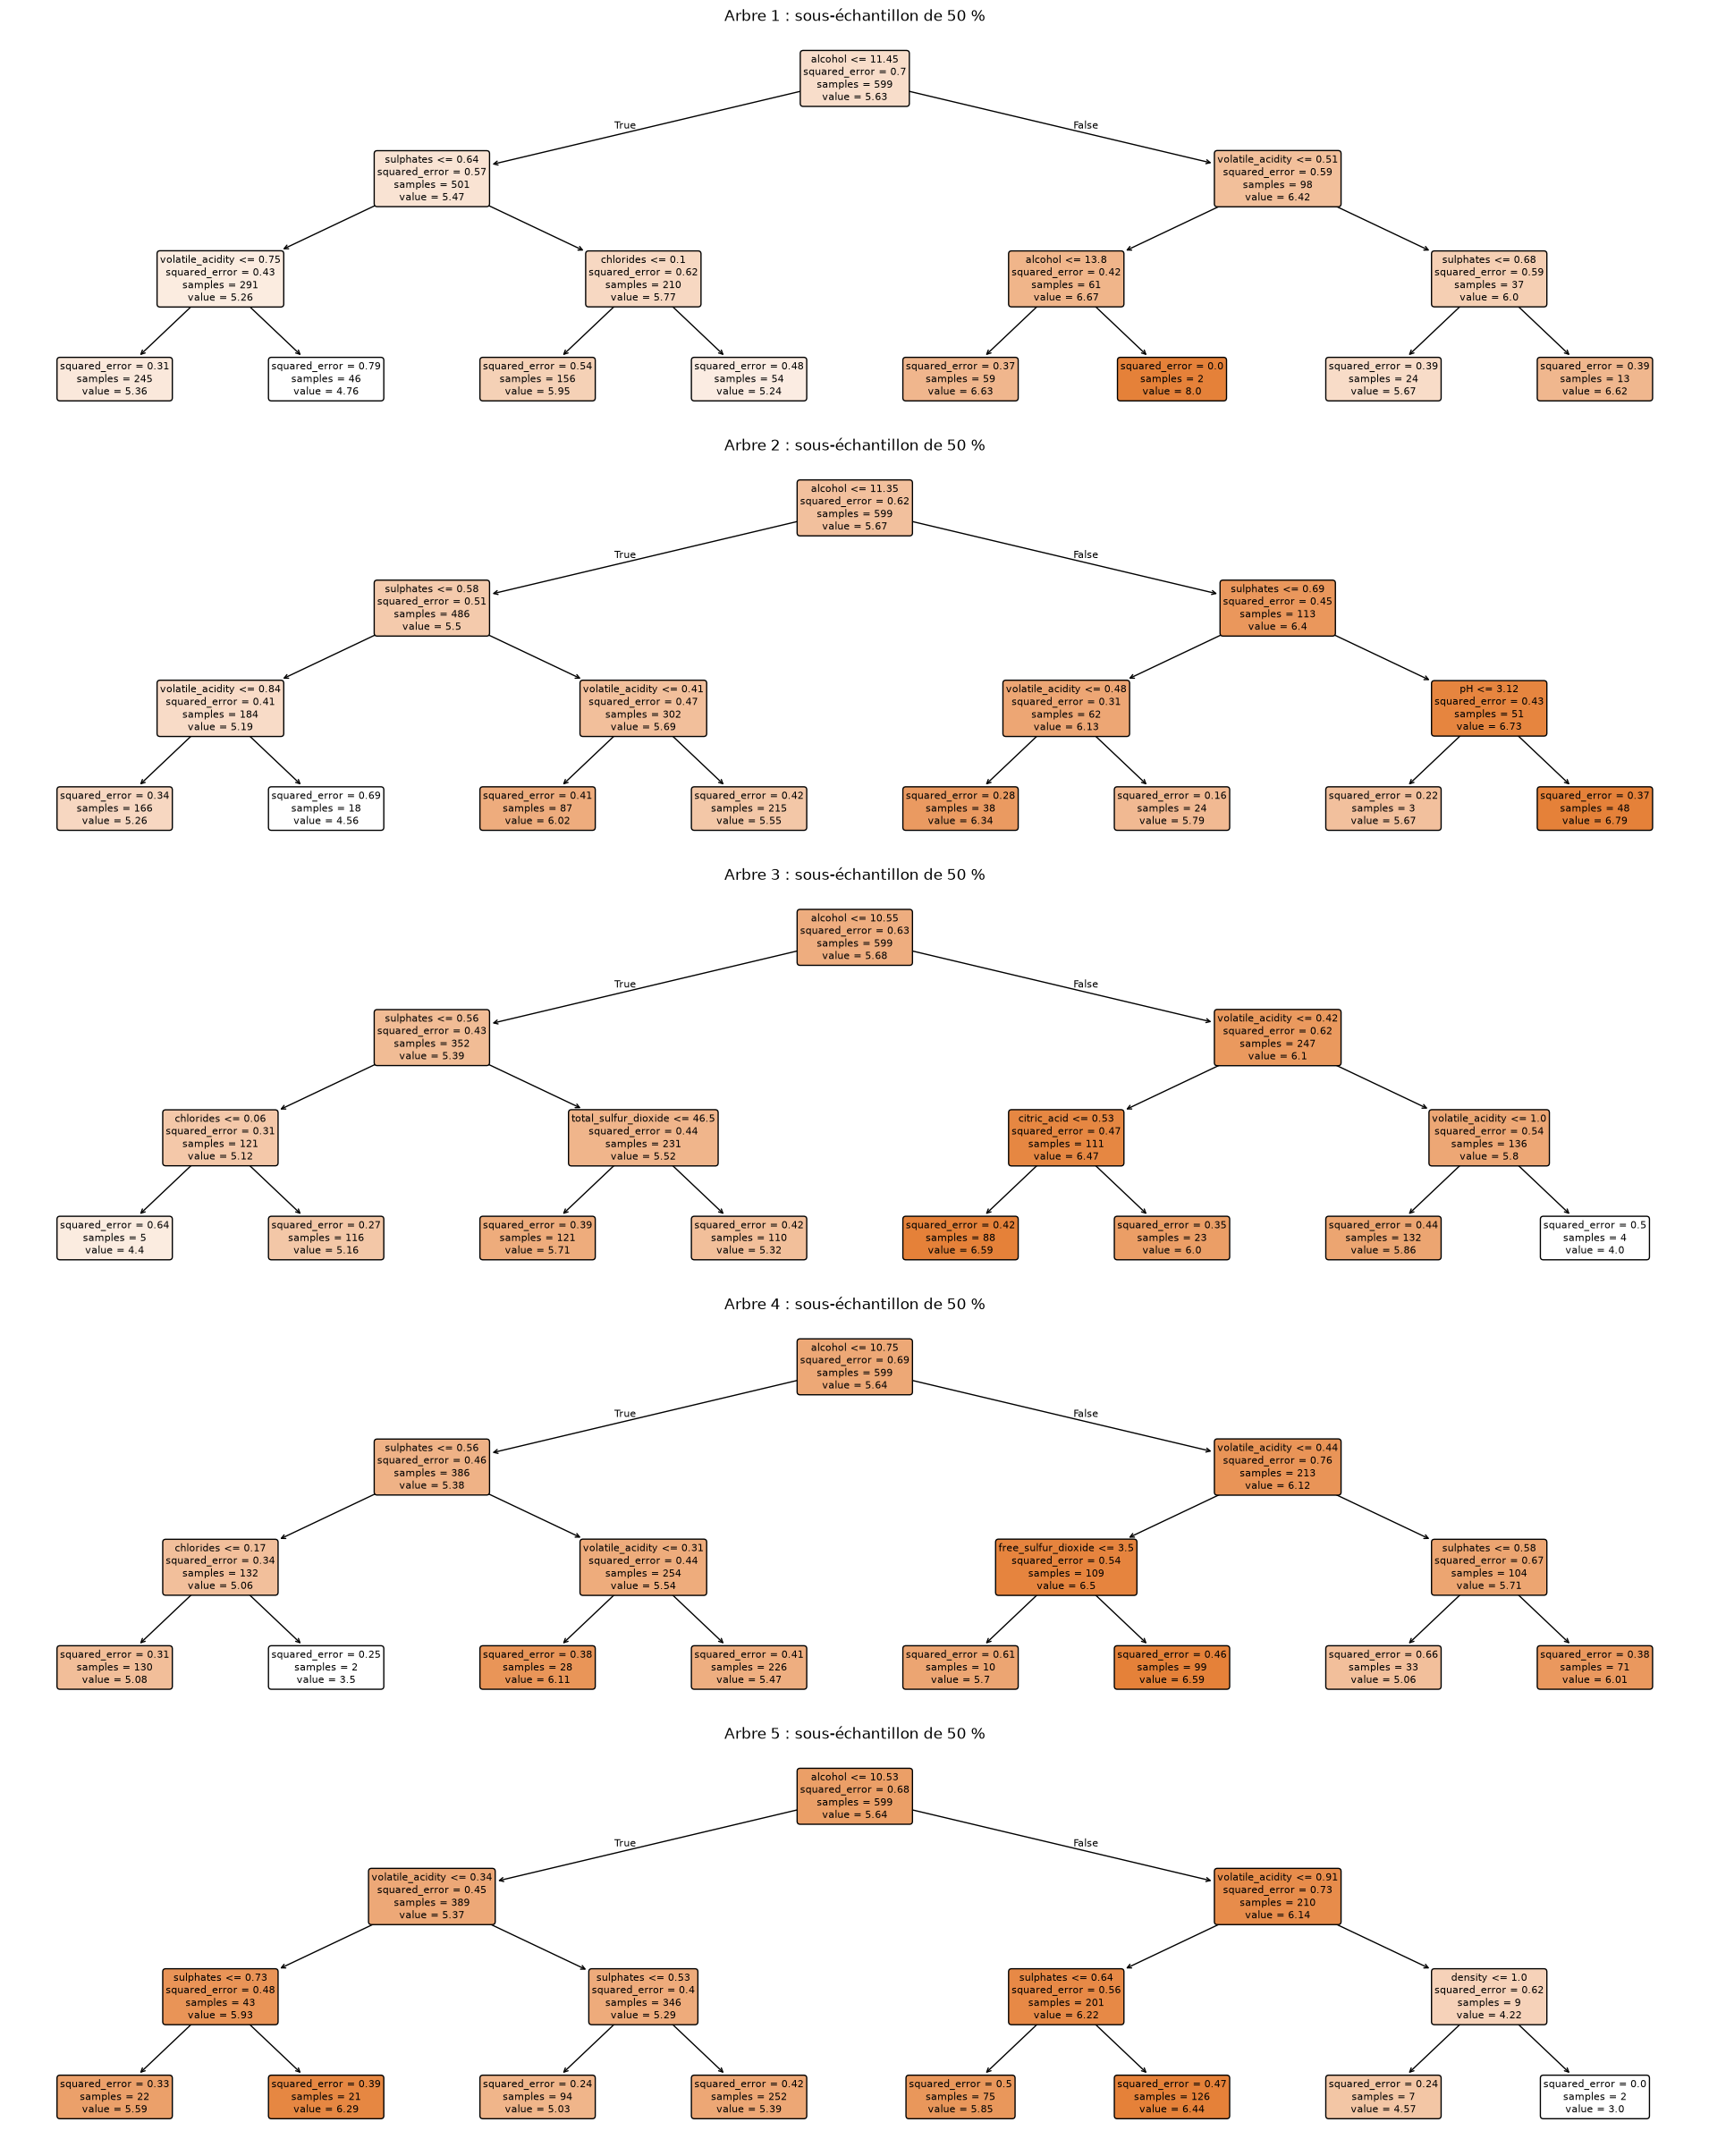

Structures de règles distinctes : 5 sur 5.
Comparez les variables et seuils à chaque profondeur, même si la racine reste identique.


In [12]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 1, figsize=(19, 24), constrained_layout=True)
signatures = []
for numero, ax in enumerate(axes, start=1):
    indices = np.random.choice(len(X_tr), size=len(X_tr) // 2, replace=False)
    arbre_echantillon = DecisionTreeRegressor(max_depth=3)
    arbre_echantillon.fit(X_tr.iloc[indices], y_tr.iloc[indices])
    structure = arbre_echantillon.tree_
    signatures.append(tuple((X_tr.columns[feature], round(structure.threshold[node], 2))
                            for node, feature in enumerate(structure.feature) if feature >= 0))
    plot_tree(arbre_echantillon, feature_names=list(X_tr.columns), filled=True,
              rounded=True, precision=2, fontsize=8, ax=ax)
    ax.set_title(f"Arbre {numero} : sous-échantillon de 50 %", fontsize=12)
plt.show()
print(f"Structures de règles distinctes : {len(set(signatures))} sur 5.")
print("Comparez les variables et seuils à chaque profondeur, même si la racine reste identique.")

### Question 3 — Forêts aléatoires

### Rappel de cours — Forêts aléatoires

Une **forêt aléatoire** agrège un grand nombre d'arbres CART entraînés sur des **échantillons bootstrap**, en
ne considérant qu'un **sous-ensemble aléatoire de variables** à chaque split (paramètre **`mtry`**). Le
**moyennage** réduit fortement la **variance** → prédictions plus robustes que l'arbre seul. Bonus : l'**erreur
Out-Of-Bag (OOB)** est une estimation « gratuite » de l'erreur de généralisation, calculée sur les données non
tirées par le bootstrap de chaque arbre.

**3.a — Hyperparamètres réglables** (équivalents `ranger`/`caret`) :
- **`max_features`** ≈ `mtry` (nb de variables candidates par split) ;
- **`min_samples_leaf`** ≈ `min.node.size` (taille minimale des feuilles) ;
- `n_estimators` (nombre d'arbres, à prendre « assez grand »).


In [13]:
# 3.b Validation croisee en faisant varier mtry (max_features) et min.node.size
grille = {
    "max_features": [3, 4, 6, 8],
    "min_samples_leaf": [1, 3, 5, 10],
}
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1)
rech = GridSearchCV(rf, grille, cv=5, scoring="neg_root_mean_squared_error")
rech.fit(X_tr, y_tr)

print("Meilleurs hyperparametres :", rech.best_params_)
print("RMSE de validation croisee :", round(-rech.best_score_, 3))

Meilleurs hyperparametres : {'max_features': 4, 'min_samples_leaf': 1}
RMSE de validation croisee : 0.584


In [14]:
# Une courbe par taille minimale de feuille ; l'axe x montre le nombre de variables candidates.
res = pd.DataFrame(rech.cv_results_)
res["rmse_cv"] = -res["mean_test_score"]
fig = go.Figure()
for taille, groupe in res.groupby("param_min_samples_leaf", sort=True):
    groupe = groupe.sort_values("param_max_features")
    fig.add_trace(go.Scatter(
        x=groupe["param_max_features"].astype(int), y=groupe["rmse_cv"],
        mode="lines+markers", name=f"min_samples_leaf = {taille}",
        hovertemplate="mtry = %{x}<br>RMSE = %{y:.3f}<extra></extra>",
    ))
fig.update_layout(
    title="RMSE en validation croisee selon mtry et la taille minimale des feuilles",
    xaxis=dict(title="max_features (~mtry)", tickmode="array", tickvals=grille["max_features"]),
    yaxis_title="RMSE en validation croisee (plus bas = meilleur)",
)
apply_dark_theme(fig)
fig.show()

**3.c & 3.d — Réentraînement optimal, erreur de généralisation et comparaison avec l'OOB.**


In [15]:
# 3.c reentrainement avec les meilleurs hyperparametres + OOB active
foret = RandomForestRegressor(n_estimators=300, n_jobs=-1, oob_score=True, **rech.best_params_)
foret.fit(X_tr, y_tr)

pred_foret = evalue(foret, "Foret aleatoire (optimisee)")
rmse_oob = np.sqrt(mean_squared_error(y_tr, foret.oob_prediction_))
print(f"RMSE Out-Of-Bag (sur apprentissage) : {rmse_oob:.3f}")
reel_vs_predit(pred_foret, "Foret aleatoire : valeurs reelles vs predites (test)", pick_color(3))

Foret aleatoire (optimisee) : RMSE = 0.582 | R2 = 0.446
RMSE Out-Of-Bag (sur apprentissage) : 0.573


**Comparaison CART vs forêt.** La forêt aléatoire obtient un **RMSE nettement plus faible** que l'arbre CART
de profondeur 3 : le moyennage de centaines d'arbres profonds (faible biais) et peu corrélés réduit la variance
et améliore la généralisation. L'**erreur OOB** est du même ordre que l'erreur de test : elle constitue un bon
substitut « gratuit » à un jeu de validation (chaque arbre est évalué sur les ~37 % d'observations absentes de
son échantillon bootstrap, car $(1 - 1/n)^n \to e^{-1} \approx 0.37$).

On remarque aussi, sur le graphique réel/prédit, que les prédictions sont **tirées vers la moyenne** (les notes
3–4 sont surestimées, les notes 8 sous-estimées) : c'est l'effet classique de la moyenne dans les feuilles quand
les notes extrêmes sont rares.

### Compléments — Importance des variables

Une forêt est moins lisible qu'un arbre, mais on peut mesurer **quelles variables comptent** :
- **MDI** (*Mean Decrease in Impurity*, `feature_importances_`) : réduction de variance cumulée apportée par
  chaque variable dans tous les arbres (calculée sur l'apprentissage, biaisée vers les variables continues à
  nombreux seuils) ;
- **importance par permutation** : dégradation du RMSE **sur le test** quand on mélange aléatoirement une
  variable (on casse son lien avec la cible). Plus fiable pour interpréter.

In [16]:
perm = permutation_importance(foret, X_te, y_te, n_repeats=10, scoring="neg_root_mean_squared_error")
importances = pd.DataFrame({
    "MDI (apprentissage)": foret.feature_importances_,
    "Permutation (hausse du RMSE test)": perm.importances_mean,
}, index=X.columns).sort_values("Permutation (hausse du RMSE test)")

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=list(importances.columns))
for i, col in enumerate(importances.columns):
    fig.add_trace(go.Bar(x=importances[col], y=importances.index, orientation="h",
                         marker_color=pick_color(i), showlegend=False), row=1, col=i + 1)
fig.update_layout(title="Importance des variables dans la foret aleatoire", height=450)
fig.show()

**Lecture.** Les deux mesures s'accordent sur l'essentiel : **`alcohol`**, **`sulphates`** et
**`volatile_acidity`** dominent, ce qui confirme l'analyse exploratoire (corrélations) et la structure de l'arbre
CART (racine sur `alcohol`). Attention : une importance mesure l'**utilité prédictive** d'une variable pour ce
modèle, pas un **effet causal** ; deux variables corrélées peuvent aussi se partager l'importance.

### Question 4 (Bonus) — Visualisation des prédictions dans un espace projeté 2D (UMAP)

Le sujet R passe par `reticulate` pour appeler le package Python **umap**. En Python, on l'utilise
directement (`umap-learn`). Cette partie est **optionnelle** : si `umap-learn` n'est pas installé, la cellule
affiche simplement un message d'installation sans erreur.

*Principe :* on **normalise** les données, on calcule une projection **supervisée** UMAP (en 2D), on définit
une grille 100×100 dans l'espace projeté, on **inverse** la projection (`inverse_transform`) pour revenir dans
l'espace des variables, on **dé-normalise**, on prédit avec la forêt, puis on affiche une **heatmap** des
prédictions.


In [17]:
if umap is None:
    print("umap-learn non installe. Pour executer ce bonus : uv add umap-learn")
else:
    scaler = MinMaxScaler().fit(X_tr)
    reducer = umap.UMAP(n_components=2)
    emb = reducer.fit_transform(scaler.transform(X_tr), y=y_tr.values)   # projection supervisee

    # Grille 100 x 100 dans l'espace UMAP -> profils reconstruits (approx.) -> prediction de la foret
    xs = np.linspace(emb[:, 0].min(), emb[:, 0].max(), 100)
    ys = np.linspace(emb[:, 1].min(), emb[:, 1].max(), 100)
    gx, gy = np.meshgrid(xs, ys)
    profils = scaler.inverse_transform(reducer.inverse_transform(np.column_stack([gx.ravel(), gy.ravel()])))
    preds_grille = foret.predict(pd.DataFrame(profils, columns=X_tr.columns)).reshape(gx.shape)

    fig = go.Figure()
    fig.add_trace(go.Contour(x=xs, y=ys, z=preds_grille, colorscale=CONTINUOUS_SCALE, opacity=0.85,
                             colorbar=dict(title="Note predite"), contours=dict(showlabels=True)))
    fig.add_trace(go.Scatter(x=emb[:, 0], y=emb[:, 1], mode="markers", name="Apprentissage",
                             marker=dict(size=6, color=y_tr, colorscale=CONTINUOUS_SCALE,
                                         line=dict(color=TEXT, width=0.3))))
    fig.update_layout(title="Predictions de la foret dans l'espace UMAP 2D", xaxis_title="UMAP 1",
                      yaxis_title="UMAP 2")
    fig.show()

## Annexe — Les entropies du cours et les coupures CART

**Quel critère pour quel problème ?** Dans ce TP, `quality` reste une note numérique : l'arbre de régression réduit la **variance** $s^2(t)$. Les entropies du cours (leçon 4, « Trees and Random Forests », pages 11-13 du cours, 9-11 du PDF) décrivent au contraire l'impureté d'un nœud de **classification**. L'exemple ci-dessous classe les vins selon `quality >= 6` uniquement pour les illustrer.

Dans un nœud $t$, $p_1,\ldots,p_M$ sont les proportions des $M$ classes (avec $0\log 0=0$). Une impureté est nulle si tous les vins ont la même classe ; elle est maximale lorsque les classes sont équiprobables :

| Notion du cours | Formule | Interprétation |
|---|---|---|
| Entropie de Shannon | $H_1(t)=-\sum_{k=1}^{M}p_k\ln p_k$ | Mesure l'incertitude sur la classe ; c'est la limite $q\to1$ de Tsallis. |
| Entropie de Tsallis | $H_q(t)=\dfrac{1-\sum_{k=1}^{M}p_k^q}{q-1}$, $q>0$, $q\ne1$ | Famille d'impuretés : $q$ modifie l'importance accordée aux proportions rares. |
| Indice de Gini | $G(t)=1-\sum_{k=1}^{M}p_k^2=H_2(t)$ | **Ce n'est pas Shannon**, mais c'est exactement Tsallis pour $q=2$. |
| Erreur de classification | $1-\max_k p_k$ | Mesure le taux d'erreur si l'on prédit la classe majoritaire ; peu sensible aux changements de proportions. |

La leçon utilise $\ln$ pour Shannon. Avec $\log_2$, la courbe est multipliée par $1/\ln 2$ : pour un même critère, le choix du meilleur split ne change pas. Pour une coupure en enfants gauche $t_G$ et droit $t_D$, CART maximise le **gain d'impureté pondéré** $\Delta I(t)=I(t)-\frac{n_G}{n}I(t_G)-\frac{n_D}{n}I(t_D)$. Cela vaut pour la variance, Shannon ou Gini, selon le type de modèle ; on ne compare pas leurs valeurs brutes entre critères.

Dans l'exemple binaire, $p=P(\mathrm{quality}\ge6\mid t)$ et $H_q(p)=\frac{1-p^q-(1-p)^q}{q-1}$. Quand $q<1$, les classes rares pèsent davantage ; quand $q>1$, leur contribution diminue. Changer de $q$ peut modifier les gains et donc les seuils, la structure de l'arbre et ses prédictions, **sans garantie d'améliorer le test**. `DecisionTreeClassifier` fournit Shannon (`criterion="entropy"` ou `"log_loss"`) et Gini (`"gini"`), mais pas un critère Tsallis de $q$ arbitraire.

**À ne pas confondre avec l'entropie croisée** de la leçon 2 (page 5 du cours, page 3 du PDF) : $\ell_{CE}(y,\hat p)=-y\ln\hat p-(1-y)\ln(1-\hat p)$ est une **perte de prédiction** binaire évaluée sur la probabilité $\hat p$ annoncée par un modèle. L'entropie de Shannon d'un nœud utilise les proportions observées des classes et sert ici à choisir une coupure ; la perte cross-entropy n'est pas un troisième critère CART de ce TP.

In [18]:
from sklearn.tree import DecisionTreeClassifier

proportions = np.linspace(0, 1, 201)
terme_p = np.zeros_like(proportions)
terme_q = np.zeros_like(proportions)
interieur = (proportions > 0) & (proportions < 1)
terme_p[interieur] = -proportions[interieur] * np.log(proportions[interieur])
terme_q[interieur] = -(1 - proportions[interieur]) * np.log(1 - proportions[interieur])

fig = go.Figure()
for nom, valeurs in [
    ("Tsallis q = 0.5", (1 - np.sqrt(proportions) - np.sqrt(1 - proportions)) / -0.5),
    ("Shannon (Tsallis q -> 1)", terme_p + terme_q),
    ("Gini (Tsallis q = 2)", 2 * proportions * (1 - proportions)),
    ("Tsallis q = 3", (1 - proportions**3 - (1 - proportions)**3) / 2),
    ("Erreur de classification", np.minimum(proportions, 1 - proportions)),
]:
    fig.add_trace(go.Scatter(x=proportions, y=valeurs, mode="lines", name=nom))
fig.update_layout(title="Impurete d'un noeud selon la proportion de vins bien notes",
                  xaxis_title="Proportion avec quality >= 6", yaxis_title="Impurete")
apply_dark_theme(fig)
fig.show()

cible_classe_tr = (y_tr >= 6).astype(int)
cible_classe_te = (y_te >= 6).astype(int)
classifieurs = {}
for critere in ("gini", "entropy"):
    classifieur = DecisionTreeClassifier(criterion=critere, max_depth=3,
                                         min_samples_leaf=20)
    classifieur.fit(X_tr, cible_classe_tr)
    classifieurs[critere] = classifieur
    racine = classifieur.tree_.feature[0]
    print(f"{critere} : racine {X_tr.columns[racine]} <= {classifieur.tree_.threshold[0]:.2f} ; "
          f"precision test = {classifieur.score(X_te, cible_classe_te):.3f} ; "
          f"feuilles = {classifieur.get_n_leaves()}")
print("Predictions test differentes (Gini vs Shannon) :",
      np.count_nonzero(classifieurs["gini"].predict(X_te) != classifieurs["entropy"].predict(X_te)))
print("Exemple de classification uniquement : le modele principal du TP reste une regression.")

gini : racine alcohol <= 10.53 ; precision test = 0.655 ; feuilles = 8
entropy : racine alcohol <= 10.53 ; precision test = 0.647 ; feuilles = 8
Predictions test differentes (Gini vs Shannon) : 7
Exemple de classification uniquement : le modele principal du TP reste une regression.


## Annexe — Comprendre UMAP et ses limites

UMAP (*Uniform Manifold Approximation and Projection*) transforme les 11 caractéristiques du vin en deux coordonnées destinées à la **visualisation**. Il part des distances entre vins normalisés, construit un graphe de voisinage dans l'espace initial, puis place les points en 2D en essayant de préserver leurs **voisins proches**. Les axes « UMAP 1 » et « UMAP 2 » n'ont pas d'unité ni d'interprétation chimique. Les distances globales entre amas et la taille des amas ne sont pas fidèlement conservées.

- **`n_neighbors`** (15 par défaut) : petit = accent sur les structures locales ; grand = voisinage plus large et vue plus globale.
- **`min_dist`** (0,1 par défaut) : petit = amas compacts ; grand = points plus étalés. Ce paramètre change l'image, **pas** les prédictions de la forêt déjà entraînée.
- la **graine globale** (`np.random.seed`, posée en début de notebook) fixe une réalisation reproductible de la projection ; la géométrie reste sensible aux paramètres et au jeu d'apprentissage.
- Avec `fit_transform(X_tr_norm, y=y_tr)`, la projection du bonus est **supervisée** : les notes d'apprentissage contribuent à rapprocher ou séparer les points. On ne doit jamais fournir `y_te` lors de l'ajustement, et la carte n'est pas une preuve indépendante de qualité prédictive.

**Lire la carte du bonus.** Les points sont les vins d'apprentissage, colorés par leur note observée ; le fond représente la note **prédite par la forêt**, pas la note réelle. Chaque position de la grille 2D est reconstruite en 11 dimensions avec `inverse_transform`, puis dénormalisée avant la prédiction. Cette inversion est **approximative** : dans les zones sans points, le profil reconstruit peut ne correspondre à aucun vin plausible. La carte illustre les variations du modèle, mais ne remplace ni la RMSE sur le jeu de test ni l'analyse des caractéristiques d'origine.

Pour comparer plusieurs vues, faire varier `n_neighbors` et `min_dist` **sur le seul apprentissage**, puis vérifier si les voisinages et les zones de prédiction restent cohérents. Ne pas interpréter une frontière sur la carte comme une règle exacte dans l'espace original.

## Annexe — Pour aller plus loin sur les arbres et les forêts

### 1. Pourquoi l’arbre coupe selon une variable et un seuil ?
À chaque étape, un arbre CART cherche la variable et le seuil qui minimisent l’impureté de la partition. En régression, cette impureté est souvent la variance de la cible dans chaque sous-région.

Autrement dit, l’arbre cherche une coupure qui rend les observations de chaque côté plus homogènes. Quand la variance diminue, la prédiction moyenne dans chaque feuille devient plus fiable.

### 2. Pourquoi les arbres surajustent-ils facilement ?
Les arbres peuvent aller très loin dans le partitionnement de l’espace, ce qui leur permet d’ajuster presque parfaitement les données d’apprentissage. Cela provoque un faible biais, mais une grande variance : un petit changement dans les données peut modifier fortement l’arborescence.

C’est précisément pourquoi la profondeur est souvent limitée, et pourquoi on utilise des méthodes comme :
- l'élagage coût-complexité (`ccp_alpha` ; `cp` dans `rpart`), voir l'annexe suivante,
- la validation croisée,
- les forêts aléatoires.

### 3. Pourquoi les forêts réduisent la variance ?
Une forêt aléatoire construit de nombreux arbres sur des sous-ensembles de données et/ou de variables. La prédiction finale est la moyenne des prédictions de tous les arbres.

Cette agrégation a un effet de stabilisation :
- chaque arbre est instable ;
- la moyenne de plusieurs arbres est beaucoup plus stable ;
- la variance globale diminue sans faire exploser le biais.

**Idée clé.** Les arbres sont très interprétables, mais souvent instables. Les forêts sont moins interprétables, mais beaucoup plus robustes.

---

### 4. Interprétation utile pour le TP
Le modèle CART ne cherche pas simplement à « faire une bonne prédiction » ; il cherche à construire une partition de l’espace très lisible. C’est pour cela qu’on peut interpréter les règles du type :

- si `alcohol < 10.2`, alors la note moyenne est plus basse ;
- si `alcohol >= 10.2` et `volatile.acidity` faible, alors la note est meilleure.

Cette lecture est fondamentale pour comprendre la logique d’un arbre : il décompose le problème en conditions successives, comme une suite de décisions.

---

## Annexe — Régler la complexité d'un arbre : l'élagage coût-complexité

Plutôt que de fixer arbitrairement `max_depth=3`, CART fait pousser un **grand arbre** $T_0$ puis l'**élague**
en minimisant le critère **coût-complexité** :
$$C_\alpha(T) = \underbrace{\sum_{\text{feuilles } t} n_t\, s^2(t)}_{\text{erreur d'ajustement}} \;+\; \alpha\,|T|,$$
où $|T|$ est le nombre de feuilles. Pour $\alpha = 0$ on garde l'arbre complet (surajustement) ; quand $\alpha$
augmente, chaque feuille « coûte » plus cher et l'arbre optimal se simplifie. On obtient ainsi une **suite
emboîtée** de sous-arbres, et on choisit $\alpha$ par **validation croisée** (`ccp_alpha` en scikit-learn,
`cp` dans `rpart`, où $\alpha$ est normalisé par l'erreur de la racine).

In [19]:
# Chemin d'elagage de l'arbre complet, puis choix de ccp_alpha par validation croisee
chemin = DecisionTreeRegressor().cost_complexity_pruning_path(X_tr, y_tr)
alphas = np.unique(np.quantile(chemin.ccp_alphas[chemin.ccp_alphas > 0], np.linspace(0, 0.99, 40)))
rech_cart = GridSearchCV(DecisionTreeRegressor(), {"ccp_alpha": alphas}, cv=5,
                         scoring="neg_root_mean_squared_error").fit(X_tr, y_tr)
arbre_elague = rech_cart.best_estimator_
print(f"ccp_alpha optimal = {rech_cart.best_params_['ccp_alpha']:.5f} | "
      f"{arbre_elague.get_n_leaves()} feuilles, profondeur {arbre_elague.get_depth()}")
evalue(arbre_elague, "Arbre elague (CV)")

fig = go.Figure(go.Scatter(x=alphas, y=-rech_cart.cv_results_["mean_test_score"], mode="lines+markers",
                           line=dict(color=pick_color(0))))
fig.add_vline(x=rech_cart.best_params_["ccp_alpha"], line_dash="dash", line_color=HIGHLIGHT,
              annotation_text="alpha optimal")
fig.update_layout(title="Elagage cout-complexite : RMSE de validation croisee selon alpha",
                  xaxis=dict(title="ccp_alpha", type="log"), yaxis_title="RMSE (CV)")
fig.show()

ccp_alpha optimal = 0.00924 | 10 feuilles, profondeur 4
Arbre elague (CV) : RMSE = 0.685 | R2 = 0.232


**Lecture.** À gauche ($\alpha$ petit) l'arbre est très profond et **surajuste** ; à droite ($\alpha$ grand) il
est réduit à quelques feuilles et **sous-ajuste**. Le minimum de la courbe donne un arbre de taille
intermédiaire, dont l'erreur de test est **du même ordre** que celle de l'arbre de profondeur 3 (un peu
meilleure ou un peu moins bonne selon le découpage : l'écart reste dans le bruit d'estimation). Surtout, il
reste nettement moins bon que la forêt : l'élagage réduit la variance d'**un** arbre, la forêt la réduit bien davantage en **moyennant**.

---

## Annexe — Illustration graphique : arbres, bagging et réduction de variance

Pour **visualiser** pourquoi une forêt est meilleure qu'un arbre seul, on prend un exemple simple de
**régression en 1D** : on veut retrouver une fonction (courbe pointillée) à partir de points bruités.

**Figure 1 — Un arbre profond *surajuste*, la forêt *lisse*.**
Un arbre non élagué crée un « escalier » qui colle au bruit (variance élevée). La forêt, moyenne de centaines
d'arbres, produit une courbe **beaucoup plus régulière**, proche de la vraie fonction.

In [20]:
# Figure 1 : un arbre profond (surajuste) vs une foret (lissee), sur un exemple 1D
f_vraie = lambda t: np.sin(2 * t) + 0.5 * t
x_app = np.sort(np.random.uniform(-3, 3, 120))
y_app = f_vraie(x_app) + np.random.normal(0, 0.35, x_app.size)
x_grille = np.linspace(-3, 3, 400)
y_vraie = f_vraie(x_grille)

arbre_illu = DecisionTreeRegressor().fit(x_app[:, None], y_app)
foret_illu = RandomForestRegressor(n_estimators=300).fit(x_app[:, None], y_app)
pred_arbre = arbre_illu.predict(x_grille[:, None])
pred_foret = foret_illu.predict(x_grille[:, None])

fig = make_subplots(rows=1, cols=2, shared_yaxes=True,
                    subplot_titles=["Un arbre profond (surajuste)", "Forêt — 300 arbres (lissée)"])
for col, (pred, coul) in enumerate([(pred_arbre, COLORWAY[1]), (pred_foret, COLORWAY[0])], start=1):
    fig.add_trace(go.Scatter(x=x_app, y=y_app, mode="markers", name="données",
                             legendgroup="d", showlegend=(col == 1),
                             marker=dict(color=MUTED, size=5, opacity=0.6)), row=1, col=col)
    fig.add_trace(go.Scatter(x=x_grille, y=y_vraie, mode="lines", name="vraie fonction",
                             legendgroup="v", showlegend=(col == 1),
                             line=dict(color=COLORWAY[2], width=2, dash="dash")), row=1, col=col)
    fig.add_trace(go.Scatter(x=x_grille, y=pred, mode="lines", name="prédiction",
                             legendgroup="p", showlegend=(col == 1),
                             line=dict(color=coul, width=3)), row=1, col=col)
fig.update_xaxes(title_text="x")
fig.update_yaxes(title_text="y", col=1)
fig.update_layout(title="Arbre seul vs forêt : la moyenne réduit la variance")
apply_dark_theme(fig, height=420)
fig.show()

**Figure 2 — Le *bagging* en action et le gain apporté par le nombre d'arbres.**
- À **gauche** : chaque arbre (traits fins gris) est entraîné sur un **échantillon bootstrap** différent, donc
  produit une courbe instable. Leur **moyenne** (trait épais) est nettement plus lisse : c'est l'idée du
  *bagging*.
- À **droite** : l'erreur de test **diminue** puis se **stabilise** quand on ajoute des arbres. Au-delà d'un
  certain nombre, en ajouter davantage ne nuit pas (pas de surajustement) mais n'apporte plus grand-chose.

In [21]:
# Figure 2 : bagging (arbres individuels + moyenne) et RMSE en fonction du nombre d'arbres
fig = make_subplots(rows=1, cols=2, subplot_titles=[
    "Bagging : arbres individuels et leur moyenne",
    "RMSE de test en fonction du nombre d'arbres",
])

# Gauche : chaque arbre de la foret voit un echantillon bootstrap different
foret_bag = RandomForestRegressor(n_estimators=15).fit(x_app[:, None], y_app)
for k, arbre_k in enumerate(foret_bag.estimators_):
    fig.add_trace(go.Scatter(
        x=x_grille, y=arbre_k.predict(x_grille[:, None]), mode="lines",
        name="arbres individuels", legendgroup="ind", showlegend=(k == 0),
        line=dict(color=MUTED, width=1), opacity=0.35, hoverinfo="skip",
    ), row=1, col=1)
fig.add_trace(go.Scatter(x=x_grille, y=foret_bag.predict(x_grille[:, None]), mode="lines",
                         name="moyenne (forêt)", line=dict(color=COLORWAY[0], width=4)), row=1, col=1)
fig.add_trace(go.Scatter(x=x_grille, y=y_vraie, mode="lines", name="vraie fonction",
                         line=dict(color=COLORWAY[2], width=2, dash="dash")), row=1, col=1)

# Droite : erreur de test quand le nombre d'arbres augmente
x_test = np.sort(np.random.uniform(-3, 3, 400))
y_test = f_vraie(x_test) + np.random.normal(0, 0.35, x_test.size)
n_arbres = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200, 300]
rmse_par_n = []
for n in n_arbres:
    rf = RandomForestRegressor(n_estimators=n).fit(x_app[:, None], y_app)
    rmse_par_n.append(np.sqrt(mean_squared_error(y_test, rf.predict(x_test[:, None]))))
fig.add_trace(go.Scatter(x=n_arbres, y=rmse_par_n, mode="lines+markers", name="RMSE test",
                         line=dict(color=COLORWAY[3], width=3), marker=dict(size=7),
                         showlegend=False), row=1, col=2)

fig.update_xaxes(title_text="x", row=1, col=1)
fig.update_yaxes(title_text="y", row=1, col=1)
fig.update_xaxes(title_text="nombre d'arbres", type="log", row=1, col=2)
fig.update_yaxes(title_text="RMSE de test", row=1, col=2)
fig.update_layout(title="Pourquoi la forêt réduit la variance")
apply_dark_theme(fig, height=430)
fig.show()